In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath('..'))

from dotenv import load_dotenv
load_dotenv()

import pandas as pd
pd.set_option('display.max_colwidth', 120)

import eval_config as config
from src.validation import load_and_validate

print('Config loaded from:', config.__file__)
print('Judge LLM:', config.JUDGE_PROVIDER, '/', config.JUDGE_MODELS[config.JUDGE_PROVIDER])

Config loaded from: c:\Users\datav\Desktop\AI_Fintech\ragas\eval_config.py
Judge LLM: openai / gpt-4o-mini


In [2]:
# Load and validate the CSV
df = load_and_validate(config.INPUT_CSV)
print(f'OK: {len(df)} rows, columns {list(df.columns)}')
df.head(3)

OK: 25 rows, columns ['user_input', 'reference', 'response', 'retrieved_contexts']


,user_input,reference,response,retrieved_contexts
0,I see a charge on my card that I never made. What do I do?,Report it within 60 days of the statement date. You get a provisional credit within 10 business days while the bank ...,You should report the unauthorized charge within 60 days of the statement date. The bank will give you a provisional...,"[To dispute an unauthorized transaction, the customer must report it within 60 days of the statement date., A provis..."
1,I lost my credit card. What should I do?,"Report it immediately. The card is blocked right away, you have zero liability for fraudulent charges reported, and ...","Report the loss immediately by phone or app. The card is blocked instantly, you are not liable for fraudulent charge...","[If a card is lost or stolen, the customer must report it immediately. The card is blocked instantly and the custome..."
2,Why was I charged an annual fee on my card?,"The Platinum card has a $95 annual fee, waived in the first year. The Classic card has no annual fee.","The Platinum card carries a $95 annual fee, which is waived only in the first year. If you have the Classic card, th...","[The Platinum card has an annual fee of $95, waived during the first year after account opening., The Classic card h..."


In [3]:
# Display the first row of the dataframe
row = df.iloc[0]
print('Question:  ', row['user_input'])
print('Reference: ', row['reference'])
print('Response:  ', row['response'])
print('Retrieved chunks:')
for i, chunk in enumerate(row['retrieved_contexts'], 1):
    print(f'  {i}. {chunk}')

Question:   I see a charge on my card that I never made. What do I do?
Reference:  Report it within 60 days of the statement date. You get a provisional credit within 10 business days while the bank investigates, which can take up to 90 days.
Response:   You should report the unauthorized charge within 60 days of the statement date. The bank will give you a provisional credit within 10 business days while it investigates, and the investigation can take up to 90 days.
Retrieved chunks:
  1. To dispute an unauthorized transaction, the customer must report it within 60 days of the statement date.
  2. A provisional credit is issued within 10 business days after a dispute is opened. Investigations may take up to 90 days.
  3. Customers can view pending and posted transactions in the mobile app.


In [ ]:
from src.evaluation import run_evaluation, save_scores

LIMIT = 10   # rows to evaluate; use None to evaluate all 25

df_eval = df.head(LIMIT) if LIMIT else df
print(f'Evaluating {len(df_eval)} rows with {config.JUDGE_MODELS[config.JUDGE_PROVIDER]}...')

scores = run_evaluation(df_eval)
save_scores(scores, config.SCORES_CSV)
print('Saved:', config.SCORES_CSV)

scores[['user_input', *config.METRICS]].round(2)

c:\Users\datav\Desktop\AI_Fintech\ragas\venv\lib\site-packages\google\auth\__init__.py:54: FutureWarning: You are using a Python version 3.9 past its end of life. Google will update google-auth with critical bug fixes on a best-effort basis, but not with any other fixes or features. Please upgrade your Python version, and then update google-auth.
  warnings.warn(eol_message.format("3.9"), FutureWarning)
c:\Users\datav\Desktop\AI_Fintech\ragas\venv\lib\site-packages\google\oauth2\__init__.py:40: FutureWarning: You are using a Python version 3.9 past its end of life. Google will update google-auth with critical bug fixes on a best-effort basis, but not with any other fixes or features. Please upgrade your Python version, and then update google-auth.
  warnings.warn(eol_message.format("3.9"), FutureWarning)
c:\Users\datav\Desktop\AI_Fintech\ragas\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedo

Evaluating 10 rows with gpt-4o-mini...


Evaluating: 100%|██████████| 30/30 [01:10<00:00,  2.34s/it]


Saved: c:\Users\datav\Desktop\AI_Fintech\ragas\data\eval_scores.csv


,user_input,context_recall,faithfulness,factual_correctness
0,I see a charge on my card that I never made. What do I do?,1.0,0.67,1.00
1,I lost my credit card. What should I do?,1.0,0.75,0.75
2,Why was I charged an annual fee on my card?,1.0,1.00,1.00
3,How much is the late payment fee?,1.0,1.00,1.00
4,What is the interest rate if I withdraw cash with my credit card?,1.0,1.00,1.00
5,How can I get a higher credit limit?,1.0,0.33,0.29
6,How is my minimum payment calculated?,1.0,1.00,0.50
7,Is there a fee when I use my card abroad?,1.0,1.00,1.00
8,Can I change my payment due date?,0.0,0.00,0.00
9,Do my reward points expire?,1.0,0.00,1.00


In [5]:
summary = scores[config.METRICS].agg(['mean', 'median', 'std']).round(2).T
summary['below_threshold'] = (scores[config.METRICS] < config.LOW_SCORE_THRESHOLD).sum()
summary['failed_calls'] = scores[config.METRICS].isna().sum()
summary

,mean,median,std,below_threshold,failed_calls
context_recall,0.90,1.00,0.32,1,0
faithfulness,0.68,0.88,0.42,4,0
factual_correctness,0.75,1.00,0.37,3,0


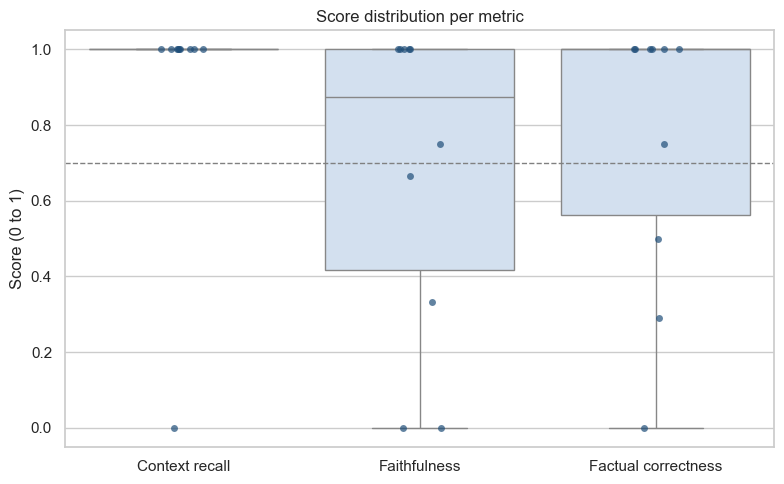

In [8]:
import matplotlib.pyplot as plt
from src.visualization import plot_boxplot

fig = plot_boxplot(scores)
fig.savefig(config.FIGURES_DIR / 'boxplot_metrics.png', dpi=150, bbox_inches='tight')
plt.show()

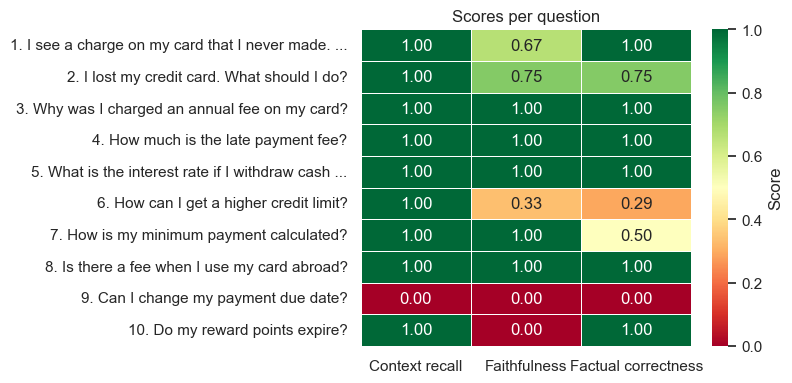

In [9]:
from src.visualization import plot_heatmap

fig = plot_heatmap(scores)
fig.savefig(config.FIGURES_DIR / 'heatmap_questions.png', dpi=150, bbox_inches='tight')
plt.show()

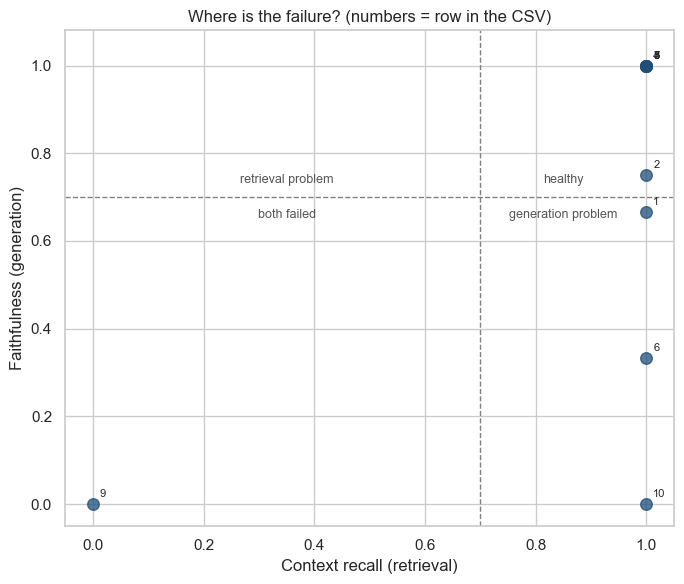

In [10]:
from src.visualization import plot_recall_vs_faithfulness

fig = plot_recall_vs_faithfulness(scores)
fig.savefig(config.FIGURES_DIR / 'scatter_recall_faithfulness.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
from src.visualization import diagnosis_counts, worst_cases

print(diagnosis_counts(scores).to_string())
worst_cases(scores, n=5)

diagnosis
ok                                     5
generation (unfaithful)                3
answer incomplete or wrong             1
retrieval + generation (unfaithful)    1


,row,user_input,response,reference,context_recall,faithfulness,factual_correctness,diagnosis
0,9,Can I change my payment due date?,"You can change your due date at any time through the app, and the new date takes effect immediately.","Yes, once every 12 months. The new date takes effect on the next billing cycle.",0.0,0.00,0.00,retrieval + generation (unfaithful)
1,6,How can I get a higher credit limit?,You can request an increase in the app after 6 months of account opening. Approval is guaranteed for customers with ...,"You are eligible 6 months after opening the account, and can request once every 6 months through the app. The review...",1.0,0.33,0.29,generation (unfaithful)
2,10,Do my reward points expire?,Your points expire only if you make no purchases for 24 consecutive months.,Points expire if there is no purchase on the account for 24 consecutive months.,1.0,0.00,1.00,generation (unfaithful)
3,2,I lost my credit card. What should I do?,"Report the loss immediately by phone or app. The card is blocked instantly, you are not liable for fraudulent charge...","Report it immediately. The card is blocked right away, you have zero liability for fraudulent charges reported, and ...",1.0,0.75,0.75,ok
4,7,How is my minimum payment calculated?,"Your minimum payment is the greater of $25 or 1% of your balance, plus any interest and fees.","The minimum payment is the greater of $25 or 1% of the balance, plus interest and fees.",1.0,1.00,0.50,answer incomplete or wrong
